# Práctica 3.1: Regresión lineal

<center><h3>
    Pablo Pardo Cotos
</h3></center>

## Instrucións

Isto é un **Jupyter Notebook**, un documento que integra código Python nun arquivo Markdown.
Isto permítenos, ir exexutando celdas de código pouco a pouco, así como xerar automáticamente un informe ben formateado da práctica.

Podes engadir unha celda co botón **"Insert"** da barra de ferramentas, e cambiar seu tipo con **"Cell > Cell Type"**

Para executar unha celda de código, seleccionarémola e pulsaremos a botón **"▶ Run"** da barra de ferramentas.
Para pasar o documento a HTML, seleccionaremos **"File > Download as > HTML (.html)"**

Segue este guión ata o final. Executa o código proporcionado paso a paso comprendendo o que estás a facer e reflexionando sobre os resultados. Haberá preguntas intercaladas ao longo do guión, responde a todas elas na sección reservada para ese fin: **"Respostas ao cuestionario"**. Por favor, non modifiques ningunha liña de código agás cando se che pida explícitamente.

Non esquezas insertar o teu **nome e apelidos** na celda superior.

## Entrega da práctica

A data límite de entrega será a indicada no Campus Virtual. A entrega consistirá nun único arquivo comprimido co nome `APELIDOS_NOME_RegresionLineal.zip` que conteña os seguintes ficheiros:

 * `APELIDOS_NOME_RegresionLineal.html`: Arquivo HTML froito da exportación do presente Notebook, coas preguntas respondidas ao final do documento.
 * `APELIDOS_NOME_RegresionLineal.ipynb`: Arquivo Jupyter Notebook fonte.
 * Arquivo de datos do problema de libre elección.

## Números aleatorios

<span style="color:red">**MOI IMPORTANTE:**</span> Vamos a establecer un *seed* cun valor predefinido inmediatamente antes de executar calquera operación cun compoñente aleatorio. Así nos aseguraremos de que os nosos resultados sexan repetibles.

Isto é, imos poñer `np.random.seed(SEED_VALUE)` antes de:
 - `train_test_split()`
 - `fit()`
 - `predict()`
 
Tamén imos poñer `random_state=SEED_VALUE` en aquelas funcións que o admitan (coma `train_test_split`).

Haberá ocasión nas que isto sexa excesivo, pero así curámonos en despistes.

# Estimación do prezo das vivendas

Neste exercicio imos asentar os conceptos vistos nas clases teóricas relativos á técnica de regresión lineal a través dun problema sinxelo. Supoñamos que somos unha inmobiliaria e queremos desenvolver unha ferramenta que nos axude a estimar un prezo recomendado de venda dos nosos inmobles. Dispomos dun pequeno dataset, `vivendas.csv`, que recolle datos de 73 vivendas vendidas pola empresa nos dous últimos anos. Neste conxunto de datos temos rexistrada a superficie total do inmoble en metros cadrados, xunto co prezo de venda en miles de euros. O noso obxectivo final é sermos capaces de, para cada novo inmoble á venda, obter un prezo recomendado de venda en base aos metros cadrados dos que dispón.

## Carga de datos e comprensión dos mesmos

Comezaremos por cargar en Python o noso conxunto de datos. O primeiro que debemos facer é asegurarnos de ter o arquivo de datos no mesmo directorio que este guión de prácticas. 

Para a carga dos datos empregamos a función `read_csv()` indicando o nome do arquivo CSV. Tamén detallamos que a primeira liña do arquivo contén os nomes das columnas (`header = 0`) e que os datos están separados por comas (`delimiter = ','`). Executa o seguinte script premendo no botón **"▶ Run"** da barra de ferramentas:

In [1]:
import pandas as pd  # Importamos a librería (isto sólo é necesario facelo unha vez)

vivendas = pd.read_csv('vivendas.csv',  # Cargamos o csv
                       delimiter=',',
                       header=0)

O dataset xa se atopa dispoñible no entorno Python. Agora poderémolo referenciar por medio do obxecto `vivendas`, do tipo `DataFrame`. Os dataframes son unha clase de obxectos especial en Python, usados como a estrutura de datos fundamental pola maioría do software de construción de modelos deste entorno. Un dataframe almacea unha táboa de datos na que cada fila corresponde a unha instancia (no noso caso vivendas) e cada columna a unha variable (superficie e prezo).

Unha boa práctica antes de comezar a construir un modelo de regresión é analizar e comprender os datos cos que imos a traballar. O primeiro que faremos, porén, será obter unha breve descripción dos mesmos:

* Número de instancias.
* Número de variables.
* Tipo de cada variable.
* Distribución de valores por cada variable.
* Correlación entre variables.

A función `.info()` do obxecto `DataFrame` danos unha primeira descrición dos datos bastante completa:

In [2]:
vivendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   superficie  73 non-null     int64  
 1   prezo       73 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.3 KB


Vemos unha descrición por columnas, indicándonos o tipo de dato de cada columna e cantos valores hai para cada unha delas. Hai outras alternativas á función anterior. Por exemplo, `.head()` tamén nos mostra as primeiras *n* instancias do noso conxunto de datos:

In [3]:
vivendas.head(n=5)

,superficie,prezo
0,81,191.73
1,117,286.90
2,99,248.93
3,85,143.29
4,116,249.61


Con `.shape` coñecemos directamente o número de filas e columnas do dataset: 

In [4]:
vivendas.shape

(73, 2)

In [5]:
print('Filas: {}'.format(vivendas.shape[0]))
print('Columnas: {}'.format(vivendas.shape[1]))

Filas: 73
Columnas: 2


Un consello útil para o futuro: cando teñas dúbidas sobre que fai ou que argumentos toma unha función, non dubides en consultar a axuda de Python con `help()`. Por exemplo:

In [6]:
help(vivendas.head)

Help on method head in module pandas.core.generic:

head(n: 'int' = 5) -> 'Self' method of pandas.DataFrame instance
    Return the first `n` rows.

    This function exhibits the same behavior as ``df[:n]``, returning the
    first ``n`` rows based on position. It is useful for quickly checking
    if your object has the right type of data in it.

    When ``n`` is positive, it returns the first ``n`` rows. For ``n`` equal to 0,
    it returns an empty object. When ``n`` is negative, it returns
    all rows except the last ``|n|`` rows, mirroring the behavior of ``df[:n]``.

    If ``n`` is larger than the number of rows, this function returns all rows.

    Parameters
    ----------
    n : int, default 5
        Number of rows to select.

    Returns
    -------
    same type as caller
        The first `n` rows of the caller object.

    See Also
    --------
    DataFrame.tail: Returns the last `n` rows.

    Examples
    --------
    >>> df = pd.DataFrame(
    ...     {
    ...  

> ❓ **_Pregunta 1._**  Indica o número de instancias e variables do dataset e o seu tipo. Investiga como acceder a valores de filas e columnas concretas dun obxecto dataframe e averigua cal foi o prezo de venda da vivenda na posición 50 do dataset. Indica o comando que empregaches para averigualo.

Tamén podemos analizar a distribución dos datos coa función `.describe()`:

In [7]:
vivendas.describe()

,superficie,prezo
count,73.000000,73.000000
mean,127.534247,162.652192
std,52.721512,108.200288
min,75.000000,51.250000
25%,91.000000,89.520000
50%,109.000000,119.730000
75%,138.000000,191.730000
max,281.000000,507.090000


> ❓ **_Pregunta 2._**  Cal é o prezo medio de venda dos inmobles? Que indican e significan *25%.*, *50%.* e *75%.* na saída da función anterior? Baseándote nos valores anteriores, cal é a mediana de superficie e a de precio?

Coa función `.plot()` podemos debuxar rapidamente un *scatter plot*, ou gráfico de dispersión, dos nosos datos:

<Axes: xlabel='superficie', ylabel='prezo'>

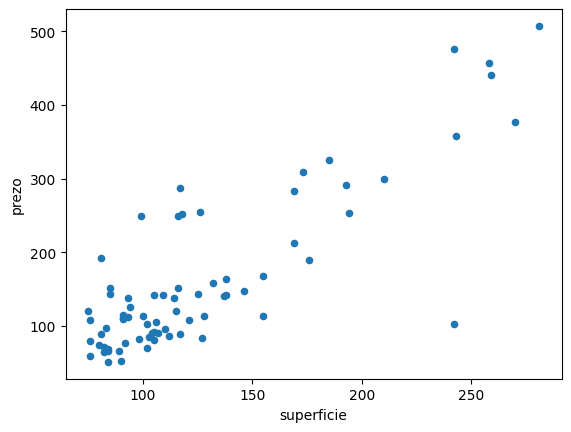

In [8]:
vivendas.plot(kind='scatter', x='superficie', y='prezo')

> ❓ **_Pregunta 3._**  Observa detidamente o gráfico anterior. Xa que se trata dun gráfico de dispersión, que poderías comentar sobre a dispersión dos datos? Dirías que existe algún tipo de relación entre as dúas variables? Xustifica a túa resposta.

Os gráficos de dispersión axúdannos a visualizar relacións lineais entre a variable a predicir e as variables preditoras. Neste caso queremos predicir o prezo do inmoble e a única variable preditora da que dispomos é a súa superficie pero, se dispuxésemos de varias variables preditoras, deberiamos debuxar un gráfico de dispersión para cada unha delas ou un gráfico en 3 dimensións no caso de que sexan 2 variables preditoras.

Para representacións deste tipo, é conveniente empregar a librería `matplotlib`.

In [9]:
import matplotlib.pyplot as plt  # Importamos a libraría (isto sólo é necesario facelo unha vez)
import numpy as np  # Importamos NumPy, para operacións matemáticas

x  = [0.         0.04081633 0.08163265 0.12244898 0.16326531]...
y1 = [1.         0.96729486 0.8713187  0.71834935 0.51839257]...
y2 = [-1.         -0.99179001 -0.96729486 -0.92691676 -0.8713187 ]...


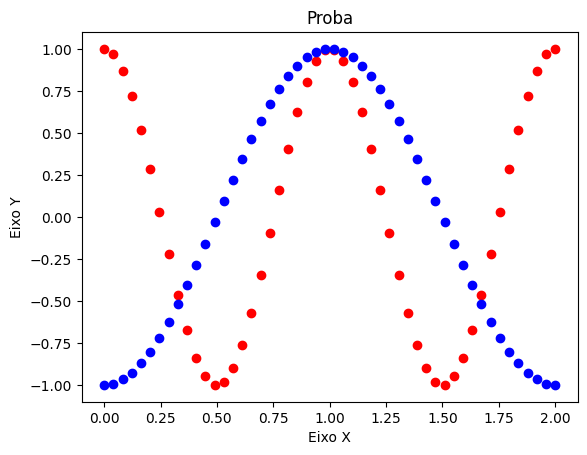

In [10]:
# Simulamos uns datos
x = np.linspace(0.0, 2.0)
y1 = np.cos(2 * np.pi * x)
y2 = np.cos(np.pi + np.pi * x)

print('x  = {}...'.format(x[:5]))
print('y1 = {}...'.format(y1[:5]))
print('y2 = {}...'.format(y2[:5]))


# Debuxamos os datos
fig = plt.figure()  # Creamos unha figura (contenedor para elementos a debuxar)
ax = fig.add_subplot(111, projection='rectilinear')  # Engadimos un Axes á figura (contén os elementos do debuxo)

ax.scatter(x, y1, color="red")  # Engadimos un scatterplot vermello
ax.scatter(x, y2, color="blue")  # Engadimos un scatterplot azul

ax.set_title("Proba")  # Poñemos un título

plt.xlabel("Eixo X")  # Nombramos os eixos
plt.ylabel("Eixo Y")

plt.show()  # Mostramos a figura por pantalla

Analizando o gráfico de dispersión das vivendas xa nos puidemos facer unha idea da dependencia entre as dúas variables. Outro xeito de analizar esta dependencia é estudando a súa correlación. A correlación é unha medida estatística que amosa o grao de dependencia lineal entre dúas variables. Esta medida pode tomar valores no rango [-1, +1]:

* Se o valor dunha das variables medra de xeito constante conforme aumenta o valor da outra, entón dicimos que teñen unha forte correlación positiva (valores próximos a +1).
* Se o valor dunha das variables diminúe de xeito constante cando o valor da outra aumenta, entón teñen unha forte correlación negativa (valores próximos a -1).
* Se as dúas variables están pouco relacionadas entón obtemos valores próximos a 0.

En Python podemos obter o coeficiente de correlación empregando a función `.corr()` dunha columna do dataframe sobre a outra columna:

In [11]:
vivendas['superficie'].corr(vivendas['prezo'])

np.float64(0.8337718450638251)

Observa como accedemos a cada unha das columnas do dataframe. 

Se traballásemos con máis de 2 variables resultaría máis doado invocar a función `.corr()` directamente sobre o dataframe, para obter unha matriz de correlacións entre cada par de variables:

In [12]:
vivendas.corr()

,superficie,prezo
superficie,1.000000,0.833772
prezo,0.833772,1.000000


## Construción dun modelo de regresión a baixo nivel

Imos construir un regresor lineal empregando o método de descenso do gradiente que xa vimos nas clases expositivas. Neste caso imos empregar as dúas variables das que dispomos directamente, pero ten en conta que habitualmente antes de adestrar un modelo realízase unha etapa de preprocesado na que, entre outras cousas, seleccionamos as instancias e as variables que queremos empregar na aprendizaxe. 

Queremos obter unha función lineal $h_\theta (x)$ (unha recta) que, a partir dos valores de superficie das vivendas, $x$, nos prediga o seu prezo máis axeitado, $y$:
  $$ y = h_\theta (x) = \theta_0 + \theta_1 x, $$
onde $\theta_0$ e $\theta_1$ son os 2 parámetros que definen a recta.

Definimos a función $h_\theta (x)$ en Python:

In [13]:
### Función de regresión lineal h ###
def h(x, th0, th1):
    return (th0 + x * th1)

Con esta función $h_\theta (x)$, se conñecésemos os valores óptimos dos dous parámetros $\theta_0$ e $\theta_1$ da recta, seriamos capaces de predecir un prezo aproximado ($y$) en base a unha superficie dada ($x$). Por exemplo, imaxina que  $\theta_0 = 0.5$ e $\theta_1 = 3$ son os valores óptimos da recta. Se temos unha vivenda de 242 metros cadrados (vivenda 24 no dataset), podemos estimar o seu prezo así:

In [14]:
h(x=242, th0=0.5, th1=3)

726.5

O prezo estimado para unha vivenda de 242 metros cadrados sería de 726500 euros. Sen embargo, o prezo real desta vivenda é:

In [15]:
vivendas.iloc[23]

superficie    242.0
prezo         475.4
Name: 23, dtype: float64

A estimación supera o prezo real do inmoble.

O problema é por tanto que non coñecemos cales son os valores reais dos parámetros, necesitamos aprendelos. Para iso, definimos unha función de custo $J(\theta_0, \theta_1)$ que guíe ao algoritmo de aprendizaxe no axuste de $\theta_0$ e $\theta_1$. Empregamos o erro cadrático medio:

In [16]:
### Erro cadrático medio ###
def ecm(reais, predicion):
    m = len(reais)  # tamaño do conxunto de datos
    erro = sum((predicion - reais)**2) / (2*m)
    return erro

### Función de custo J ###
def j(x, y, th0, th1):
    pred = h(x, th0, th1)  # predición realizada co noso regresor lineal h
    erro = ecm (y, pred)
    return erro

Por último, creamos unha función que implemente o descenso do gradiente, método que nos permitirá axustar a recta que mellor aproxima a nube de puntos:

In [17]:
### Implementación do método do descenso do gradiente ###
def desc_grad(x, y, alpha=0.00001, iteracions=35):
    # Inicializamos os coeficientes a 0
    theta0 = 0
    theta1 = 0
    hist_custos = []
    
    for i in range(iteracions):
        # Calculamos o erro cometido coa función de custo
        custo = j(x, y, theta0, theta1)
        hist_custos.append(custo)
        
        ## Actualizamos os valores dos coeficientes theta0 e theta1 
        pred = h(x, theta0, theta1)  # predición realizada co noso regresor lineal h
        m = len(x)                # tamaño do conxunto de datos
        theta0 = theta0 - alpha * sum(pred-y) / m
        theta1 = theta1 - alpha * sum((pred-y) * x) / m
        
        
        # Graficamos a iteración
        if i%2 == 0 or i == iteracions:  # Graficamos de 2 en 2 pasos
            fig = plt.figure(figsize=(20, 5))
            ax1 = fig.add_subplot(121, projection='rectilinear')
            ax2 = fig.add_subplot(122, projection='rectilinear')

            ax1.scatter(x, y, color="red")
            line_x_vals = np.array(ax1.get_xlim())
            line_y_vals = theta0 + theta1 * line_x_vals
            ax1.plot(line_x_vals, line_y_vals, '--')
            ax1.set_title("Iteración {}:     y = {} + {} * x".format(i, theta0, theta1))
            ax1.set_xlabel("prezo")
            ax1.set_ylabel("superficie")

            ax2.plot(range(i+1), hist_custos, '--', color="green")
            ax2.set_title("Custo: {}".format(custo))
            ax2.set_xlabel("iteración")
            ax2.set_ylabel("custo")

            plt.show()

Agora, simplemente chamamos á función anterior pasándolle como datos a superficie e prezo das vivendas:

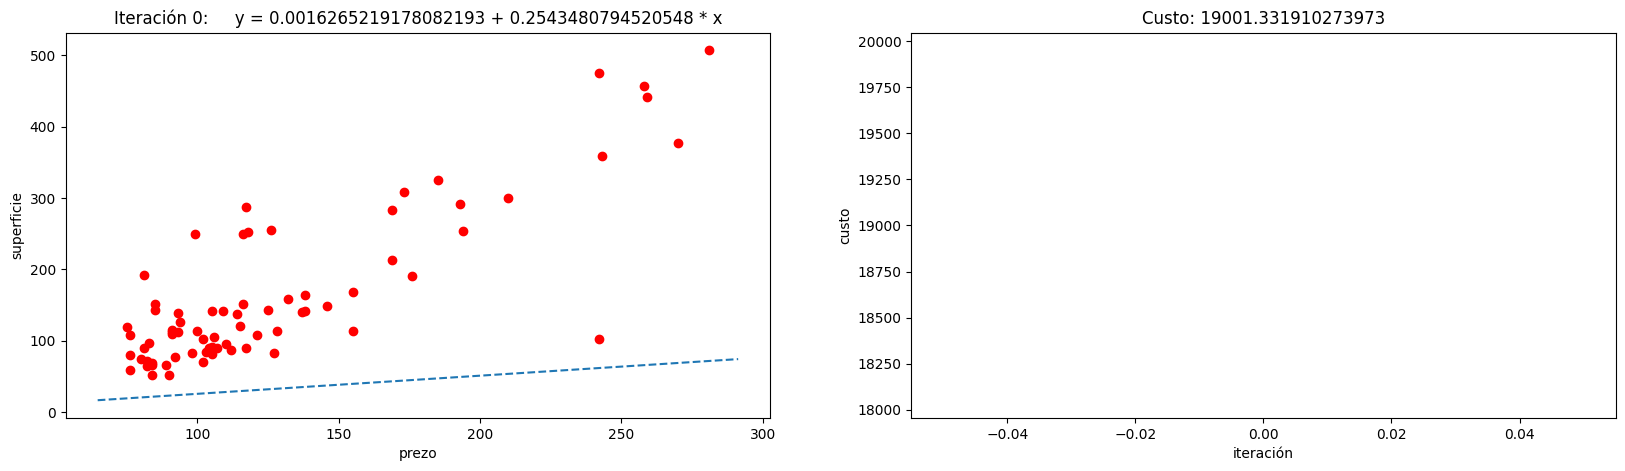

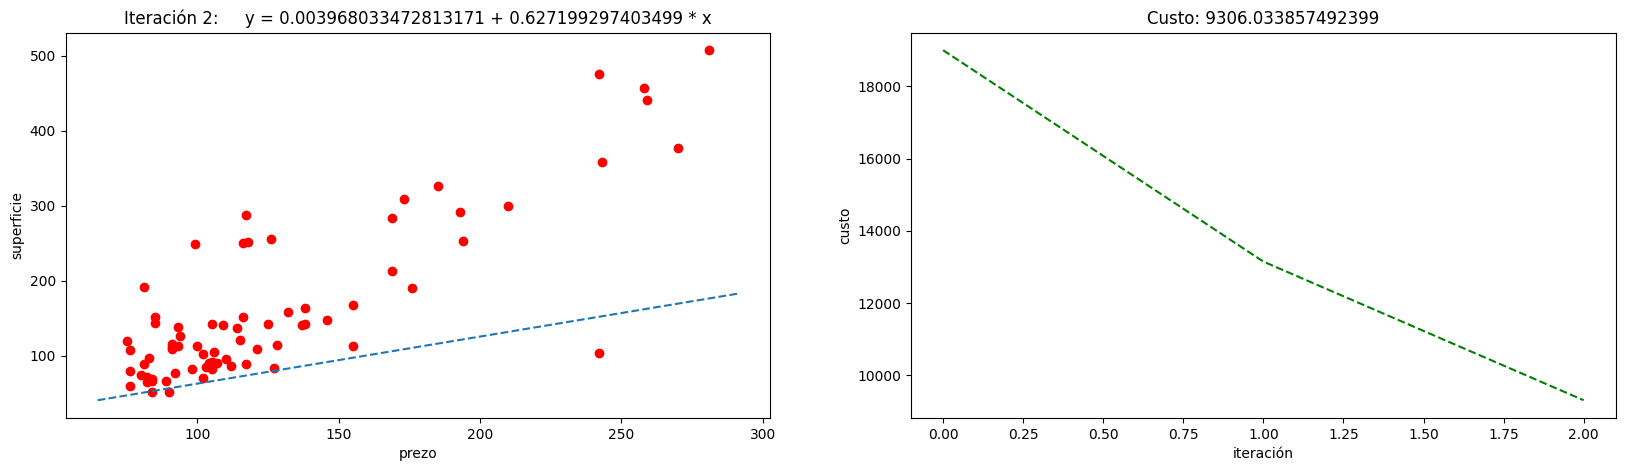

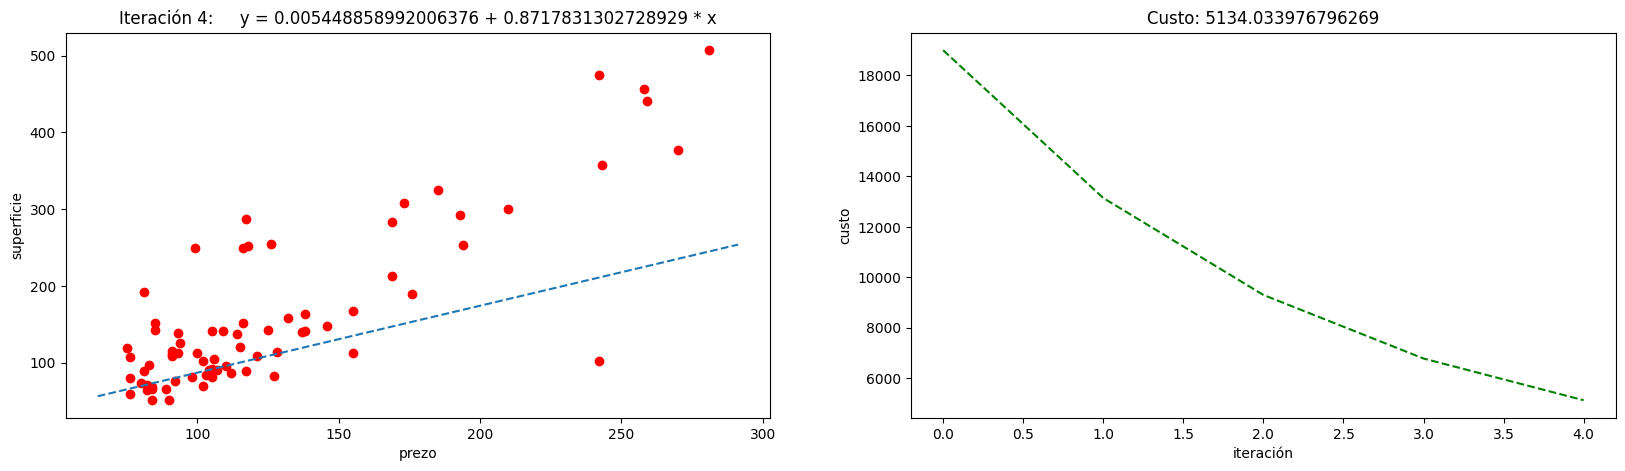

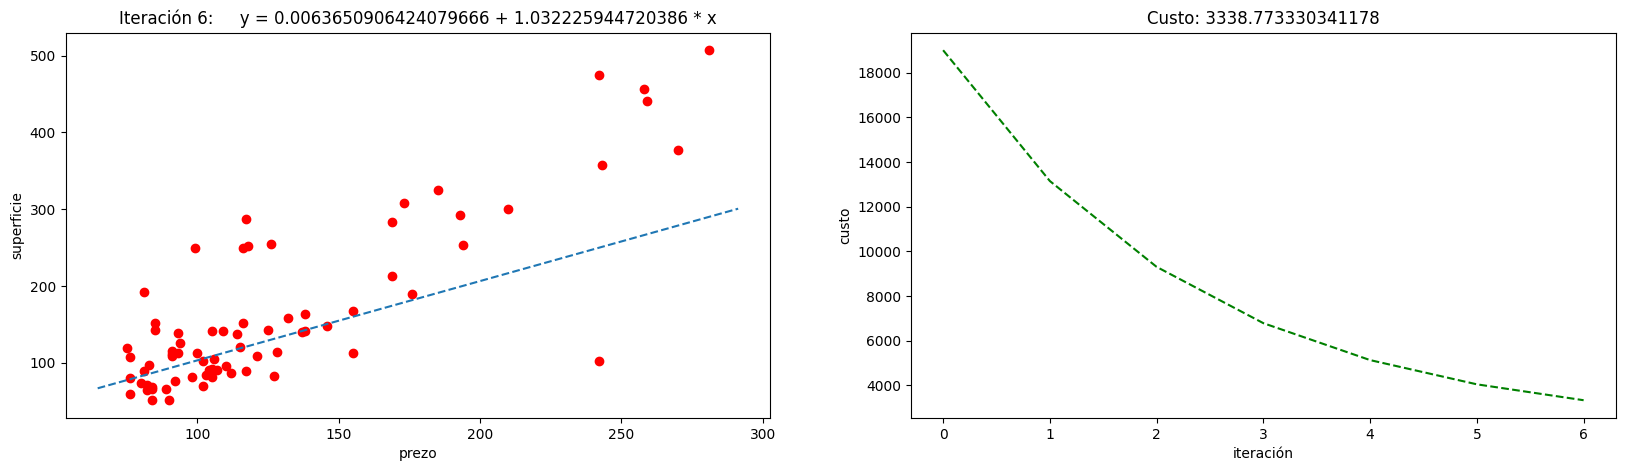

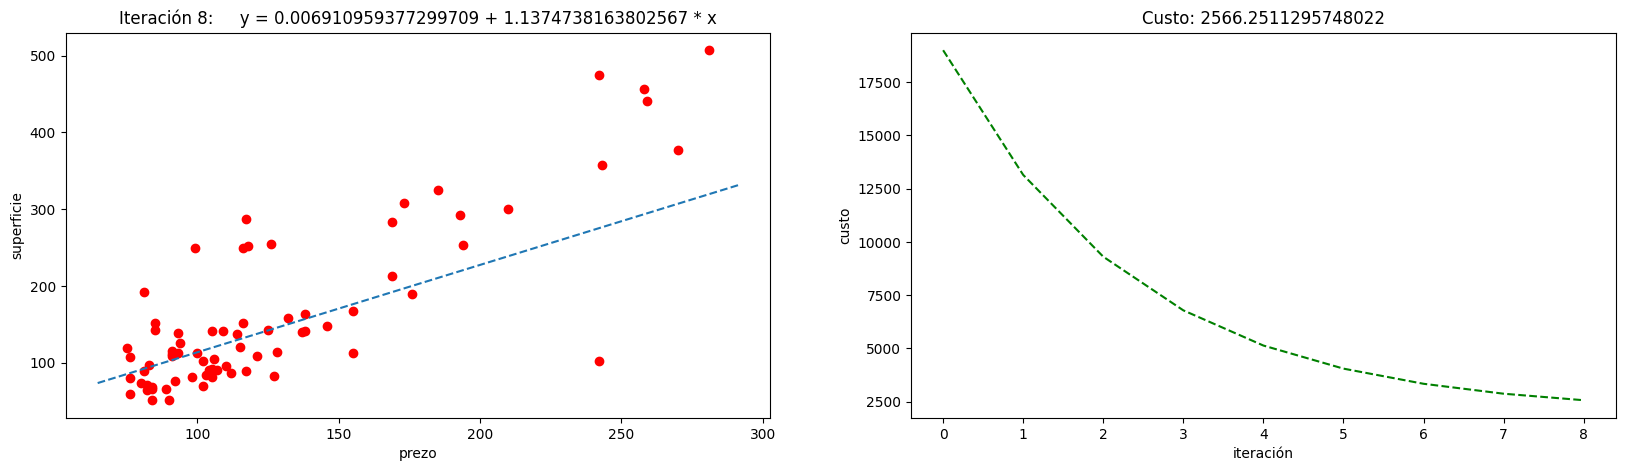

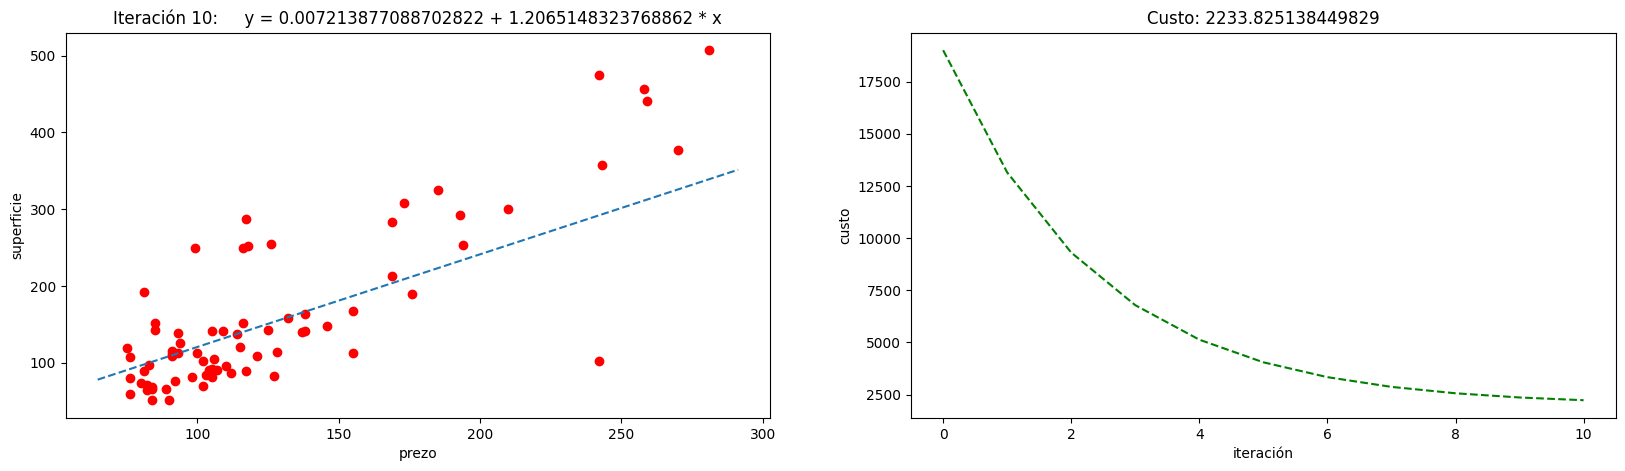

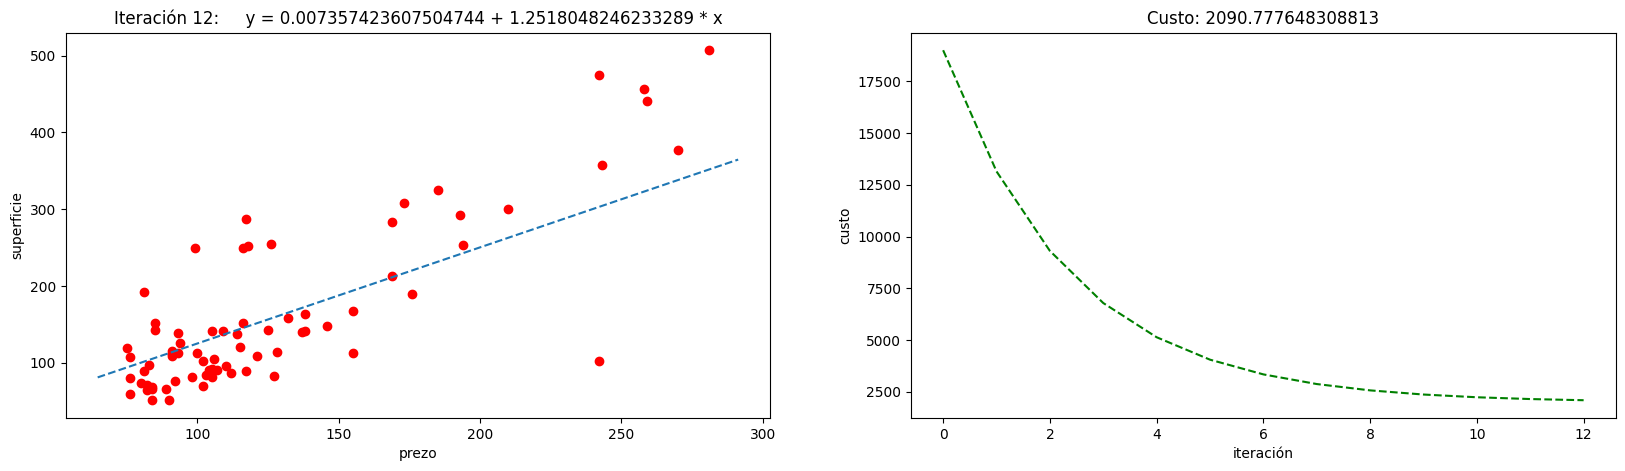

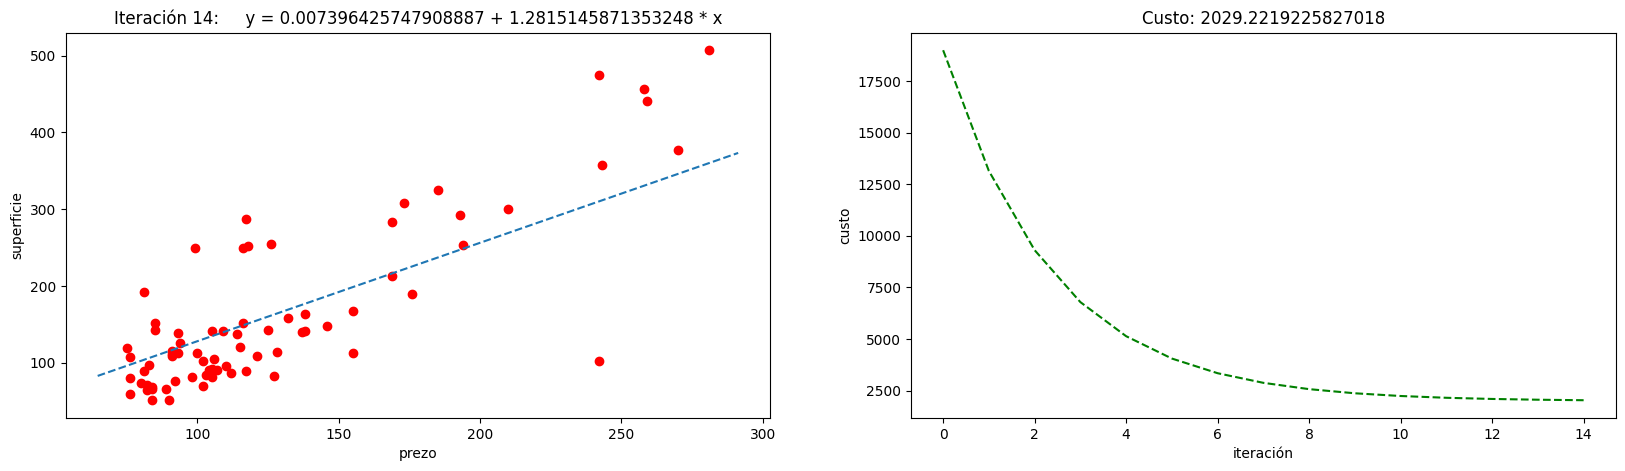

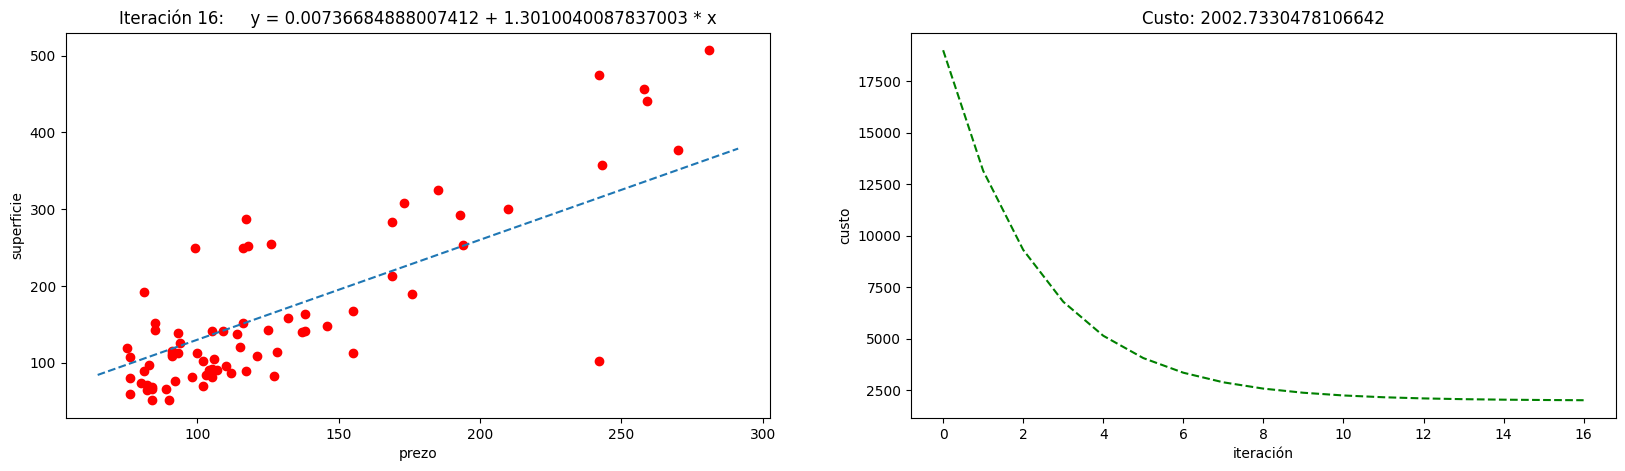

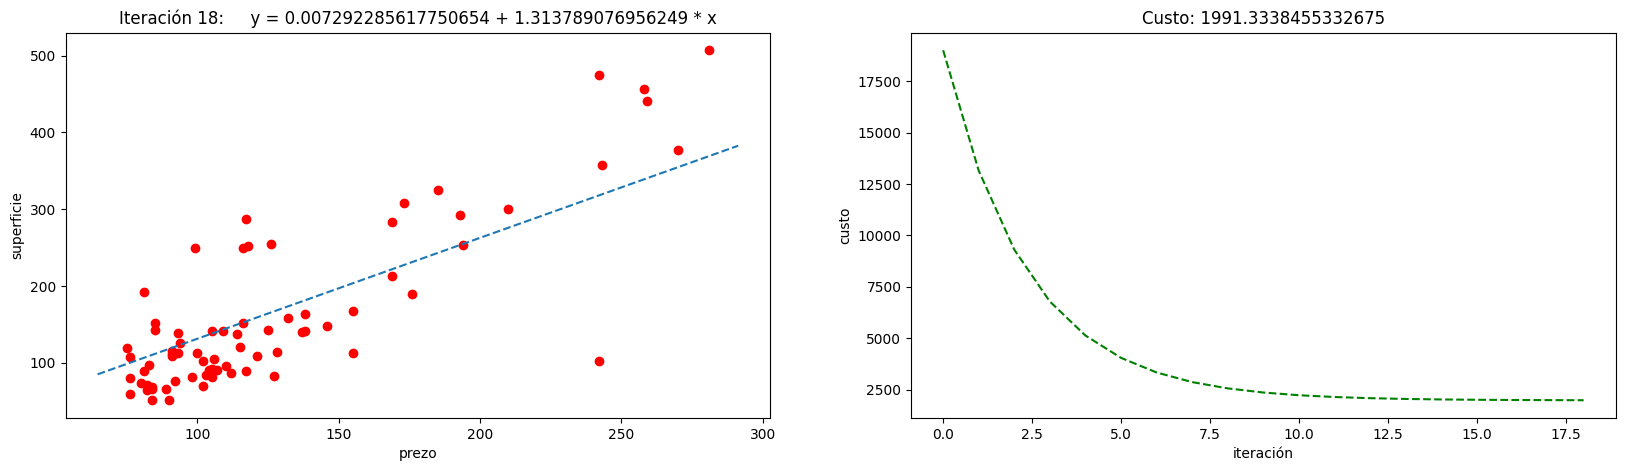

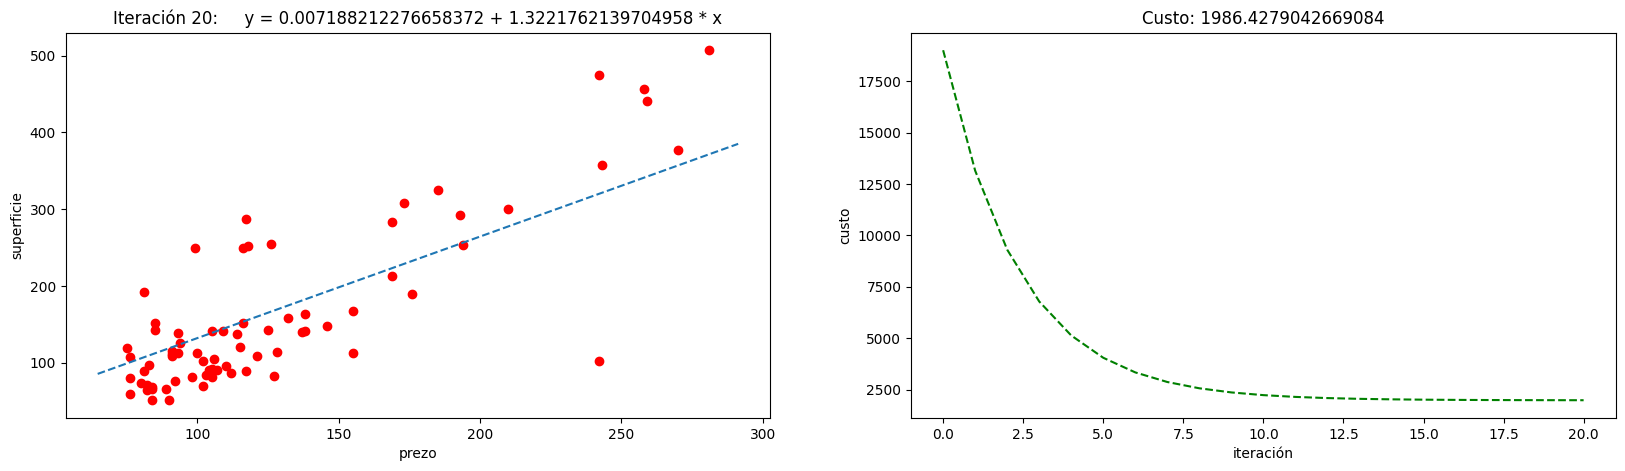

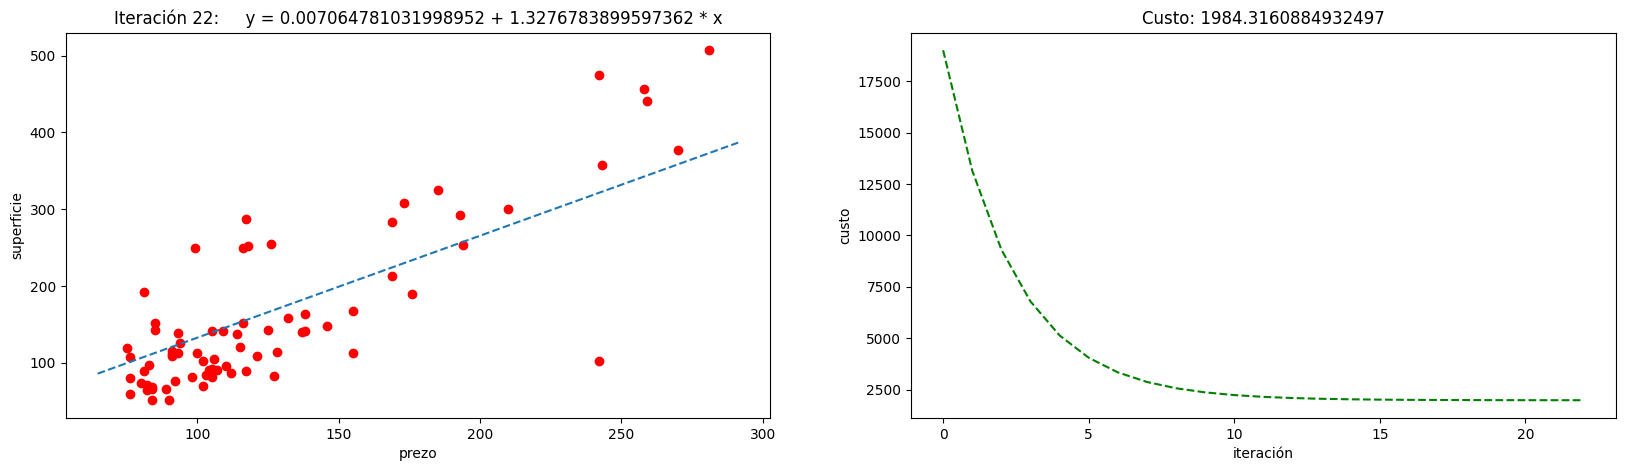

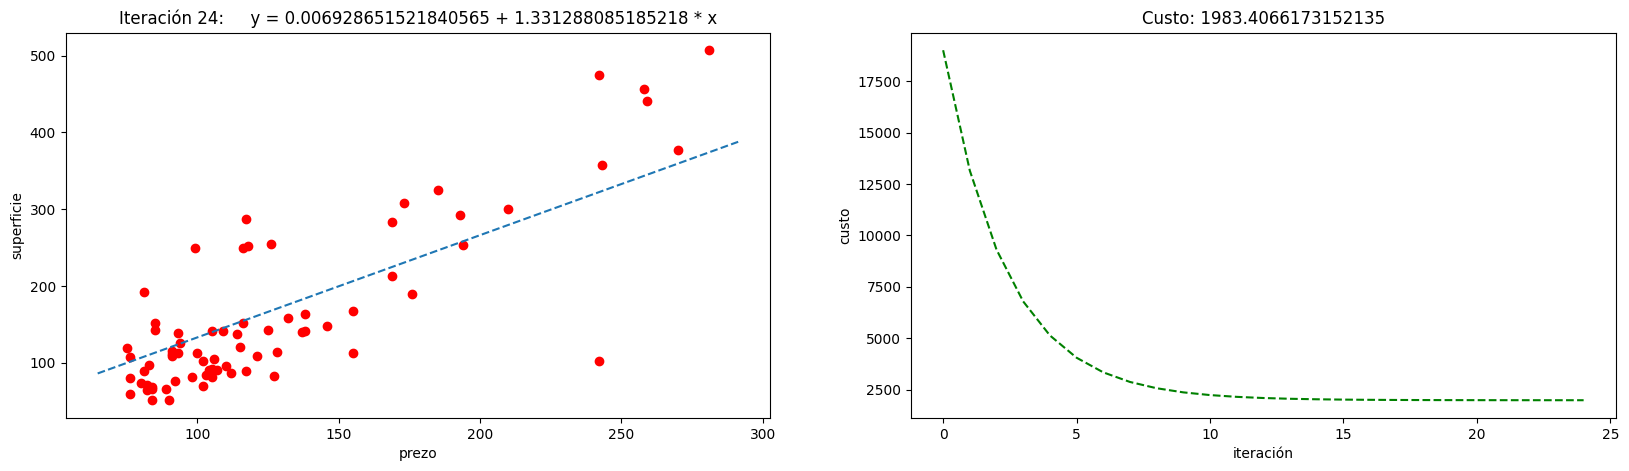

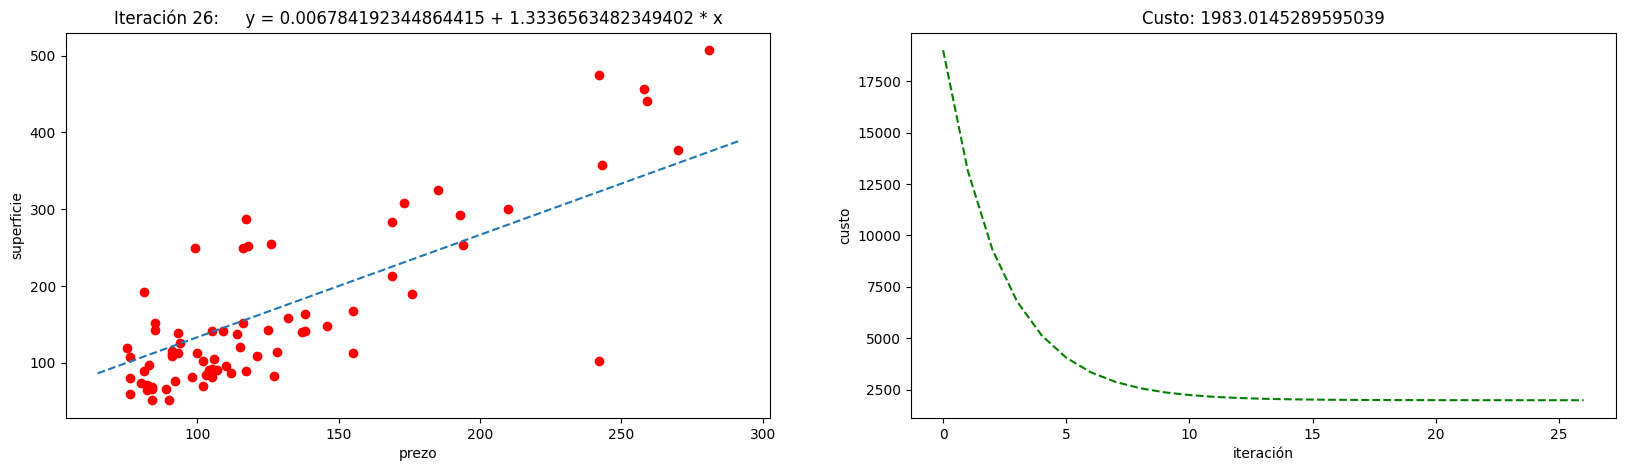

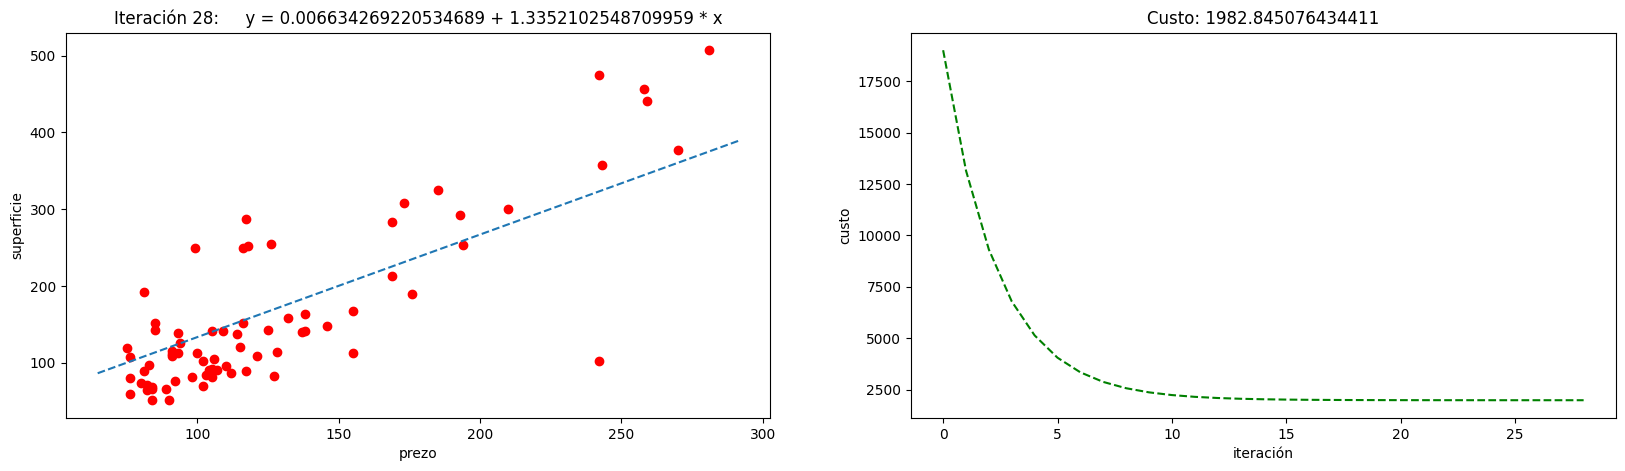

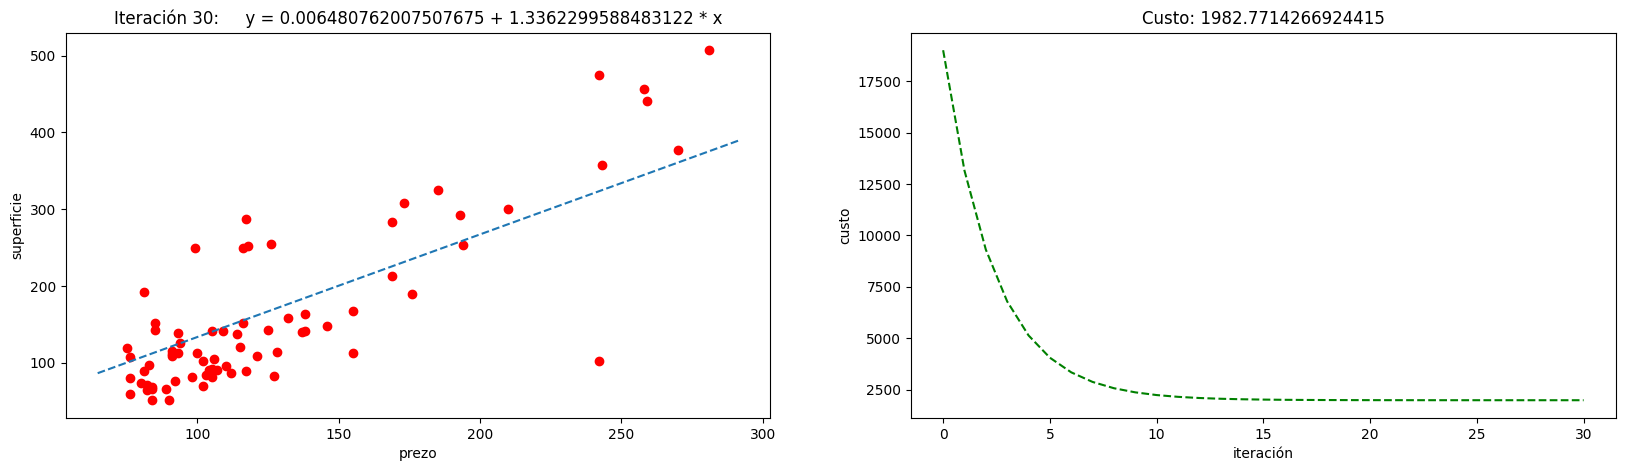

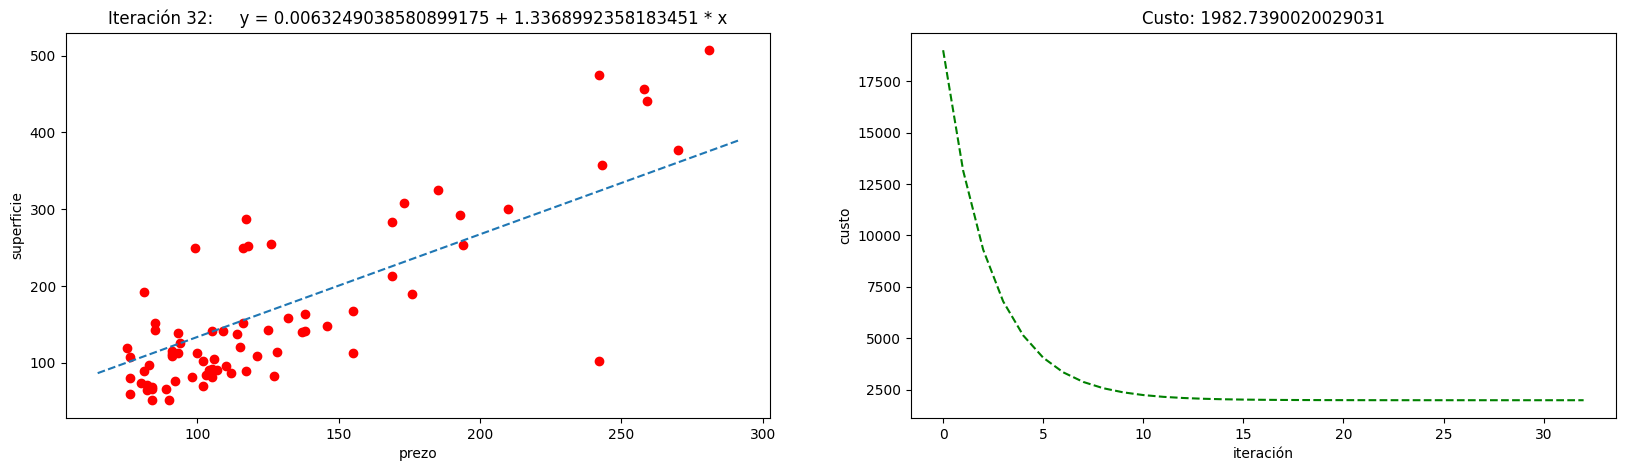

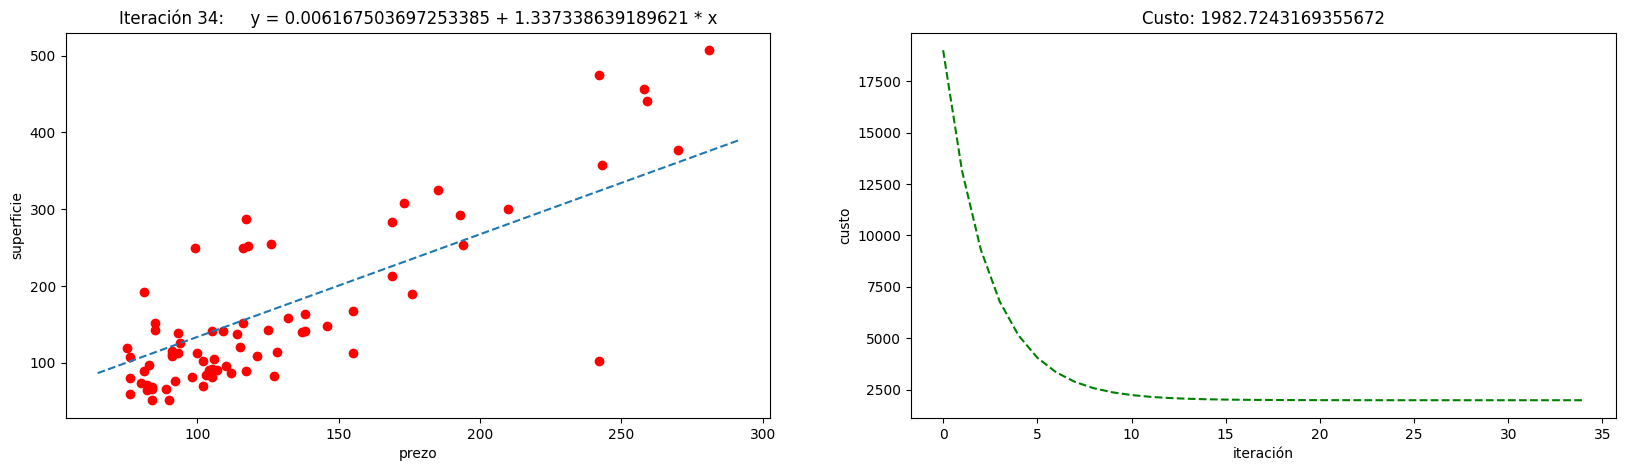

In [18]:
desc_grad(vivendas['superficie'], vivendas['prezo'], alpha = 0.00001, iteracions = 35)

> ❓ **_Pregunta 4._**  Explica brevemente e coas túas palabras como funciona o método de descenso do gradiente. Axúdate do problema das vivendas e das gráficas anteriores na túa explicación.

> ❓ **_Pregunta 5._**  Proba a executar o algoritmo variando o parámetro *alpha* ($\alpha$) e o número de iteracións (podes editar o script anterior ou crear outro na sección de respostas). Analiza os resultados. Cal é a función do parámetro $\alpha$? Que sucede con valores de $\alpha$ máis grandes (por exemplo, $\alpha = 0.01$)? Cantas iteracións dirías que son necesarias para obter unha regresión aceptable?

## Construción dun modelo con `LinearRegression`

A libraría `scikit-learn` facilítanos a construción de modelos con funcións xa programadas, de xeito que non é preciso que implementemos o descenso do gradiente a man. Imos repetir o proceso anterior empregando agora a clase `sklearn.linear_model.LinearRegression`. A súa invocación é moi simple:

In [19]:
from sklearn.linear_model import LinearRegression  # Importamos a clase (isto sólo é necesario facelo unha vez)
from sklearn.metrics import classification_report

# Dividimos o dataset en variables predictoras e dependentes
vivendas_X = vivendas.loc[:, :'superficie'].astype(float)
vivendas_Y = vivendas.loc[:, 'prezo']

model = LinearRegression()  # Definimos o modelo
model.fit(vivendas_X, vivendas_Y)  # Axustamos o modelo aos datos

# Resumo do modelo
coef = pd.DataFrame([model.intercept_, *model.coef_], ['(Intercept)', *vivendas_X.columns], columns=['Coefficients'])
coef

,Coefficients
(Intercept),-55.577885
superficie,1.711149


> ❓ **_Pregunta 6._**  Explica moi brevemente a saída deste último script. 

## Avaliación do modelo

Ata agora vimos como construir un modelo de regresión lineal empregando todo o dataset. Sen embargo, se o facemos deste xeito non temos forma de obter unha medida realista de como vai render o modelo con datos novos. Porén, unha boa práctica é dividir o dataset en dous conxuntos, un de adestramento (*training*) e outro de test. Habitualmente resérvase arredor do 70% dos datos para adestramento e o 30% restante para test, aínda que isto son só referencias xerais. O modelo é construído empregando o conxunto de adestramento e posteriormente é avaliado sobre o conxunto de test.


En Python podemos crear os subconxuntos de adestramento e test coa axuda da función `train_test_split()` da libraría `scikit-learn`, para así tomar unha mostra aleatoria dos datos. Para obter todos os mesmos resultados definimos unha semente coa función `random.seed()` de `NumPy`. Deste xeito, non importa cantas veces executemos o script, `train_test_split` sempre fará a mesma selección.

In [20]:
from sklearn.model_selection import train_test_split
SEED_VALUE = 123  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados

np.random.seed(SEED_VALUE)
vivendas_train, vivendas_test = train_test_split(vivendas, test_size=0.3, random_state=SEED_VALUE)

print('Tamaño train: {}'.format(vivendas_train.shape[0]))
print('Tamaño test: {}'.format(vivendas_test.shape[0]))

Tamaño train: 51
Tamaño test: 22


Construimos o modelo empregando só o conxunto de adestramento:

In [21]:
# Dividimos o dataset en variables predictoras e dependentes
vivendas_train_X = vivendas_train.loc[:, :'superficie'].astype(float)
vivendas_train_Y = vivendas_train.loc[:, 'prezo']

model = LinearRegression()  # Definimos o modelo
np.random.seed(SEED_VALUE)
model.fit(vivendas_train_X, vivendas_train_Y)  # Axustamos o modelo aos datos

# Resumo do modelo
coef = pd.DataFrame([model.intercept_, *model.coef_], ['(Intercept)', *vivendas_train_X.columns], columns=['Coefficients'])
coef

,Coefficients
(Intercept),-34.426839
superficie,1.510870


Agora predicimos os valores das vivendas do conxunto de validación coa axuda da función `.predict()`:

In [22]:
# Dividimos o dataset en variables predictoras e dependentes
vivendas_test_X = vivendas_test.loc[:, :'superficie'].astype(float)
vivendas_test_Y = vivendas_test.loc[:, 'prezo']

np.random.seed(SEED_VALUE)
predicions = model.predict(vivendas_test_X)

A función anterior simplemente obtén os prezos das vivendas do conxunto de test a partires da función de regresión lineal que axusta o modelo. Observa que outra forma de facer esta predición é empregando a función $h_\theta(x)$ que definimos antes indicando os coeficientes $\theta_0$ e $\theta_1$ do noso modelo:

In [23]:
predicions2 = h(vivendas_test_X, th0=coef['Coefficients']['(Intercept)'], th1=coef['Coefficients']['superficie'])

As predicións dos conxuntos `predicions` e `predicions2` deberían coincidir:

In [24]:
print('Predicións obtidas coa función .predict():')
print(predicions)
print()
print('Predicións obtidas coa función h:')
print(predicions2.to_numpy()[:, 0])

Predicións obtidas coa función .predict():
[257.17108422 119.68190805 119.68190805 332.71458762 258.68195429
 165.00801008 127.23625839 331.20371755  80.39928628 140.834089
 121.19277811  92.48624682 282.85587538 124.21451825 142.34495906
 125.72538832 142.34495906 220.91020259 131.76886859 139.32321893
 356.8885087   86.44276655]

Predicións obtidas coa función h:
[257.17108422 119.68190805 119.68190805 332.71458762 258.68195429
 165.00801008 127.23625839 331.20371755  80.39928628 140.834089
 121.19277811  92.48624682 282.85587538 124.21451825 142.34495906
 125.72538832 142.34495906 220.91020259 131.76886859 139.32321893
 356.8885087   86.44276655]


Como dispomos das predicións dos prezos das vivendas do conxunto de test e tamén coñecemos os seus prezos reais, agora podemos avaliar o rendemento do noso modelo. Por exemplo, podemos empregar de novo o erro cadrático medio: 

In [25]:
e_cadratico = ecm(vivendas_test_Y, predicions)
print(e_cadratico)

1775.6429474014146


O problema do erro cadrático medio é que non resulta un indicador moi intuitivo. Sen embargo, podemos calcular a súa raíz cadrada para obter unha estimación do erro en miles de euros:

In [26]:
np.sqrt(e_cadratico)

np.float64(42.13837855686209)

Outra posibilidade é empregar o índice de correlación entre os datos reais e as predicións:

In [27]:
vivendas_test_Y.corr(pd.Series(predicions, vivendas_test_Y.index))

np.float64(0.9160621867265677)

Como vemos, o índice de correlación é practicamente 1, polo que podemos afirmar que ambos vectores están moi correlacionados positivamente. Isto é sinal de que estamos a realizar boas predicións.

> ❓ **_Pregunta 7._**  Por que non sería axeitado avaliar o rendemento do noso modelo empregando os mesmos datos cos que o adestramos?

## Identificación de valores atípicos (*outliers*)

Os valores atípicos, anómalos ou *outliers* son instancias do noso conxunto de datos que non seguen a tendencia habitual do dataset, sendo numéricamente distantes ao resto dos datos. Noutras palabras, son instancias que parecen inconsistentes co resto dos valores do dataset. Debemos evitar que o noso conxunto de adestramento presente estes datos atípicos xa que poden deteriorar moito a calidade dos nosos modelos. 

Imos ver un exemplo sinxelo de como identificar *outliers* e analizaremos o seu impacto na calidade do modelo do prezo das vivendas. Ten en conta que esta é unha etapa habitual no preprocesado dos datos. Nós excepcionalmente ímola abordar agora aínda, tras ter un modelo, con fins ilustrativos.

Os diagramas de caixa, ou *boxplots*, son gráficos baseados en cuartiles que nos permite visualizar a distribución do conxunto de datos para cada unha das variables. En Python podemos visualizalos coa función `boxplot()` de `matplotlib`:

/var/folders/zg/g2xkvjcn3fl94hsj4jlpl7y40000gn/T/ipykernel_31018/3394143401.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(vivendas_train, labels=vivendas_train.columns)


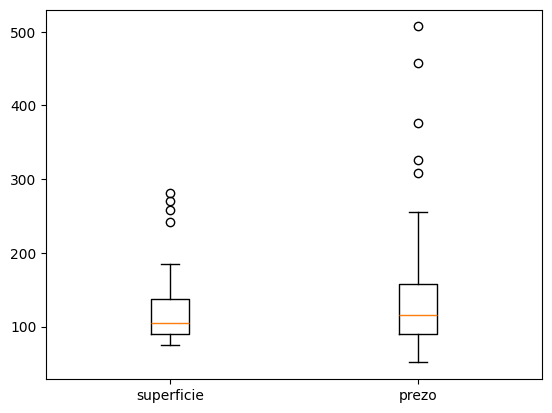

In [28]:
box = plt.boxplot(vivendas_train, labels=vivendas_train.columns)

Dentro da caixa atópase o 50% dos datos. Os datos máis atípicos (círculos) están fora dos brazos da caixa. Vemos que ambas variables presentan uns poucos *outliers* na súa distribución. Estes *outliers* coñécense como univariados porque están presentes na distribución dunha soa variable. Podemos saber os valores deses *outliers* do seguinte xeito:

In [29]:
out_superficie = box["fliers"][0].get_data()[1]
out_prezo = box["fliers"][1].get_data()[1]

print("Outliers na variable 'superficie': {}".format(out_superficie))
print("Outliers na variable 'prezo': {}".format(out_prezo))

Outliers na variable 'superficie': [258. 270. 242. 281.]
Outliers na variable 'prezo': [308.53 457.11 376.51 325.61 507.09]


Así coñecemos as superficies e prezos atípicas. Agora ben, que un exemplo sexa *outlier* nalgunha das dimensións non implica que sexa realmente un dato atípico no noso problema. Por exemplo, que unha vivenda teña unha superficie de 281 metros cadrados pode ser un valor atípico da dimensión Superficie se a maioría das vivendas son pequenas no dataset. Do mesmo modo, unha vivenda que custe preto de 500.000 euros pode ser atípica se o precio medio da vivenda é moito inferior. 

Os *outliers* dos que realmente nos temos que preocupar son aqueles *outliers* multivariados, é dicir, que disten da tendencia nas dúas dimensións, superficie-prezo. Existen métodos de identificación de outliers en máis dunha dimensión pero, debido á súa complexidade, quedan fora desta práctica. Posto que o noso problema conta con poucas instancias, podemos facer unha inspección visual e manual:

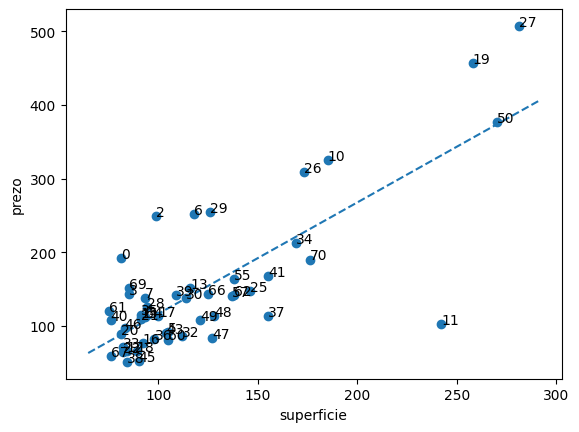

In [30]:
# Creamos o entorno
fig = plt.figure()  # Creamos unha figura (contenedor para elementos a debuxar)
ax = fig.add_subplot(111, projection='rectilinear')  # Engadimos un Axes á figura (contén os elementos do debuxo)
plt.xlabel("superficie")  # Nombramos os eixos
plt.ylabel("prezo")

# Debuxamos o scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Creamos e mostramos a recta
line_x_vals = np.array(ax.get_xlim())
line_y_vals = coef['Coefficients']['(Intercept)'] + coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--')

# Imprimimos os identificadores
for i in vivendas_train.index:
    ax.text(vivendas_train['superficie'][i], vivendas_train['prezo'][i], i)

plt.show()

Se nos fixamos no gráfico de dispersión, existe un valor moito máis distante da recta de regresión que o resto:

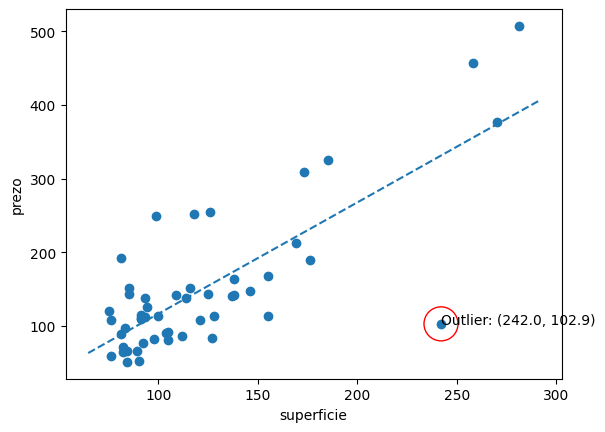

In [31]:
# Creamos o entorno
fig = plt.figure()  # Creamos unha figura (contenedor para elementos a debuxar)
ax = fig.add_subplot(111, projection='rectilinear')  # Engadimos un Axes á figura (contén os elementos do debuxo)
plt.xlabel("superficie")  # Nombramos os eixos
plt.ylabel("prezo")

# Debuxamos o scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Mostramos a recta
ax.plot(line_x_vals, line_y_vals, '--')

# Marcamos o outlier
outlier_id = 11
outlier = vivendas_train.loc[outlier_id]
ax.scatter(outlier['superficie'], outlier['prezo'], s=600, facecolors='none', edgecolors='r')
ax.text(outlier['superficie'], outlier['prezo'],
        'Outlier: ({}, {})'.format(outlier['superficie'], outlier['prezo']))
plt.show()

Imos ver se podemos mellorar a calidade do modelo prescindindo deste dato atípico. Eliminámolo do conxunto de adestramento e adestramos un novo modelo:

In [32]:
# Eliminamos o outlier do conxunto
vivendas_train = vivendas_train.drop(outlier_id)

# Dividimos o dataset en variables predictoras e dependentes
vivendas_train_X = vivendas_train.loc[:, :'superficie'].astype(float)
vivendas_train_Y = vivendas_train.loc[:, 'prezo']

new_model = LinearRegression()  # Definimos un novo modelo
new_model.fit(vivendas_train_X, vivendas_train_Y)  # Axustamos o novo modelo aos datos

# Resumo do modelo
new_coef = pd.DataFrame([new_model.intercept_, *new_model.coef_], ['(Intercept)', *vivendas_train_X.columns], columns=['Coefficients'])
new_coef

,Coefficients
(Intercept),-59.680167
superficie,1.759946


Graficamos para ver a diferenza entre o novo modelo sen o outlier e o vello:

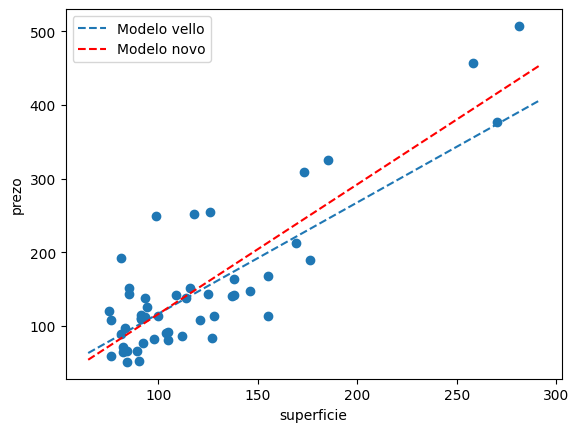

In [33]:
# Creamos o entorno
fig = plt.figure()  # Creamos unha figura (contenedor para elementos a debuxar)
ax = fig.add_subplot(111, projection='rectilinear')  # Engadimos un Axes á figura (contén os elementos do debuxo)
plt.xlabel("superficie")  # Nombramos os eixos
plt.ylabel("prezo")

# Debuxamos o scatter
ax.scatter(vivendas_train['superficie'], vivendas_train['prezo'])

# Creamos e mostramos a recta antiga
line_x_vals = np.array(ax.get_xlim())
line_y_vals = coef['Coefficients']['(Intercept)'] + coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--', label='Modelo vello')

# Creamos e mostramos a recta nova
line_y_vals = new_coef['Coefficients']['(Intercept)'] + new_coef['Coefficients']['superficie'] * line_x_vals
ax.plot(line_x_vals, line_y_vals, '--', color='r', label='Modelo novo')

ax.legend()  # Facemos que se mostren as labels

plt.show()

Realizamos de novo a predición sobre o conxunto de test e avaliamos o rendemento:

In [34]:
novas_predicions = new_model.predict(vivendas_test_X)
e_cadratico_novo = ecm(vivendas_test_Y, novas_predicions)

print(np.sqrt(e_cadratico_novo))
vivendas_test_Y.corr(pd.Series(novas_predicions, vivendas_test_Y.index))

37.012141302915026


np.float64(0.9160621867265676)

> ❓ **_Pregunta 8._**  Analiza brevemente o impacto do *outlier* no modelo de regresión.

**************************************************************

# Respostas ao cuestionario

**LEMBRA:** Non esquezas de escribir teu nome e apelidos na segunda celda do presente documento.

**Pregunta 1**

Hay **73 instancias** (viviendas) y **2 variables**: `superficie`, de tipo entero (`int64`), y `prezo`, de tipo decimal (`float64`). Ambas son numéricas y no tienen valores nulos.

Para acceder a filas y columnas concretas se puede usar `iloc` (por posición, empezando en 0) o `loc` (por la etiqueta del índice y el nombre de la columna). El precio de venta de la vivienda en la posición 50 es de **376,51 miles de euros** (376.510 €), obtenido con el comando:
```python
vivendas.iloc[50]['prezo']
```

**Pregunta 2**

El precio medio de venta de los inmuebles es de **162,65 miles de euros** (`mean`).

Los valores 25%, 50% y 75% son los cuartiles: si ordenamos los valores de una variable de menor a mayor, indican el valor por debajo del cual queda ese porcentaje de los datos. El 25% es el primer cuartil (una cuarta parte de las viviendas está por debajo), el 50% es la mediana, es decir, el valor central que deja la mitad de los datos por debajo y la otra mitad por encima, y el 75% es el tercer cuartil (tres cuartas partes de los datos quedan por debajo y solo el 25% por encima).

La mediana de la superficie es **109 m²** y la del precio, **119,73 miles de euros**.

**Pregunta 3**

Sí, hay relación entre las dos variables, y es **lineal y positiva**: los puntos suben de izquierda a derecha, así que las viviendas más grandes suelen ser más caras. A grandes rasgos, el precio sube entre 1,6 y 2 miles de euros por cada metro cuadrado más.

Los datos no están repartidos por igual. La mayoría de las viviendas son pequeñas (entre 75 y 150 m²) y baratas (entre 50 y 170 miles de euros), y ahí los puntos están bastante juntos. Las viviendas grandes son pocas y sus precios varían mucho más. Además, algunos puntos no siguen la tendencia, como una vivienda de 242 m² que cuesta solo 102,9 miles de euros, o algunas de unos 100-125 m² que cuestan entre 250 y 290 miles de euros.

Los puntos no forman una recta perfecta, pero la relación es fuerte, como confirma la correlación de 0,83 que se calcula más adelante.

**Pregunta 4**

El descenso del gradiente busca los valores de $\theta_0$ y $\theta_1$ que hacen mínimo el error de la recta, es decir, la función de coste $J$. Para ello parte de unos valores iniciales ($\theta_0 = \theta_1 = 0$) y, en cada iteración, calcula la derivada de $J$ respecto a cada parámetro y los mueve en la dirección contraria, que es hacia donde el error baja. El tamaño de cada paso lo marca $\alpha$: si es muy grande el algoritmo puede diverger, y si es muy pequeño es seguro pero muy lento.

En el problema de las viviendas, se ve en las gráficas de la izquierda cómo la recta empieza plana y en cada iteración se va inclinando hasta atravesar la nube de puntos. En las de la derecha, el coste baja muy rápido al principio (de unos 19.000 a unos 2.200 en 10 iteraciones) y luego casi no cambia (unos 1.983 al final), porque ya está cerca del mínimo.

**Pregunta 5**

La función de $\alpha$ es controlar el tamaño de cada paso del descenso del gradiente, es decir, cuánto cambian $\theta_0$ y $\theta_1$ en cada iteración. Con un $\alpha$ pequeño el algoritmo avanza muy despacio: con $\alpha = 0.000001$ y 35 iteraciones el coste todavía es de unos 6.400 y la recta queda muy por debajo de los puntos, mientras que con $\alpha = 0.00001$ llega a unos 1.983. Con un $\alpha$ demasiado grande, como $\alpha = 0.01$, cada paso se pasa del mínimo: $\theta_1$ salta de positivo a negativo cada vez más lejos y el coste se dispara (más de $10^{49}$ en solo 10 iteraciones), es decir, el algoritmo diverge.

En cuanto a las iteraciones, con $\alpha = 0.00001$ el coste baja muy rápido al principio y a partir de unas 20 iteraciones casi no cambia (1.986 en la 20 y 1.983 en la 35), así que unas 20-25 iteraciones bastan para una regresión aceptable. Aun así, $\theta_0$ casi no se mueve de 0, por lo que la recta pasa prácticamente por el origen y todavía no es la óptima; para ajustarlo harían falta muchísimas más iteraciones.

In [35]:
# Versión de desc_grad sin gráficas, para probar muchas combinaciones de alpha e iteraciones
def desc_grad_sin_graficas(x, y, alpha, iteracions):
    theta0 = 0
    theta1 = 0
    m = len(x)
    for i in range(iteracions):
        pred = h(x, theta0, theta1)
        theta0 = theta0 - alpha * sum(pred-y) / m
        theta1 = theta1 - alpha * sum((pred-y) * x) / m
    return theta0, theta1, j(x, y, theta0, theta1)

# Pruebas (alpha, iteraciones)
pruebas = [(0.000001, 35), (0.000001, 100), (0.00001, 10), (0.00001, 35), (0.00001, 100), (0.0001, 35), (0.01, 10)]
for alpha, iteracions in pruebas:
    th0, th1, custo = desc_grad_sin_graficas(vivendas['superficie'], vivendas['prezo'], alpha, iteracions)
    print('alpha = {}, iteraciones = {}, theta0 = {}, theta1 = {}, coste = {}'.format(alpha, iteracions, th0, th1, custo))

alpha = 1e-06, iteraciones = 35, theta0 = 0.0041114535239259115, theta1 = 0.654547459085951, coste = 6424.210124536317
alpha = 1e-06, iteraciones = 100, theta0 = 0.006859726942037203, theta1 = 1.141787342798214, coste = 2349.2321236083594
alpha = 1e-05, iteraciones = 10, theta0 = 0.007086743523801801, theta1 = 1.1756195106278526, coste = 2233.825138449829
alpha = 1e-05, iteraciones = 35, theta0 = 0.006167503697253385, theta1 = 1.337338639189621, coste = 1982.7201922648571
alpha = 1e-05, iteraciones = 100, theta0 = 0.0009622689876398678, theta1 = 1.338209414890517, coste = 1982.6717773714192
alpha = 0.0001, iteraciones = 35, theta0 = -0.01884381397515201, theta1 = 1.3728070135305455, coste = 1993.7992595804992
alpha = 0.01, iteraciones = 10, theta0 = -5.2424641206923697e+20, theta1 = -7.812800193920052e+22, coste = 5.801281168305699e+49


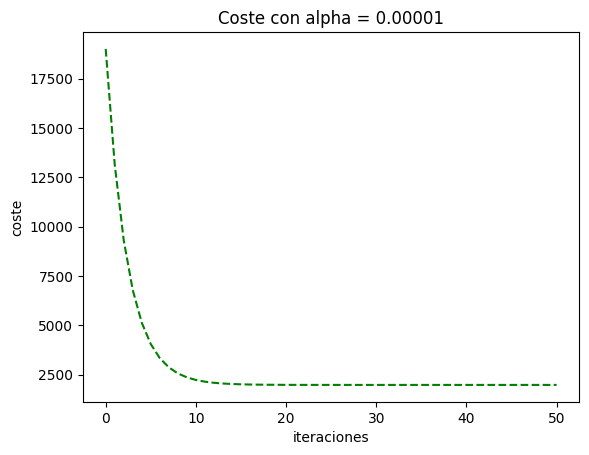

In [36]:
# Coste en función del número de iteraciones con alpha = 0.00001
iteracions = range(0, 51)
custos = [desc_grad_sin_graficas(vivendas['superficie'], vivendas['prezo'], 0.00001, n)[2] for n in iteracions]

plt.plot(iteracions, custos, '--', color="green")
plt.title("Coste con alpha = 0.00001")
plt.xlabel("iteraciones")
plt.ylabel("coste")
plt.show()

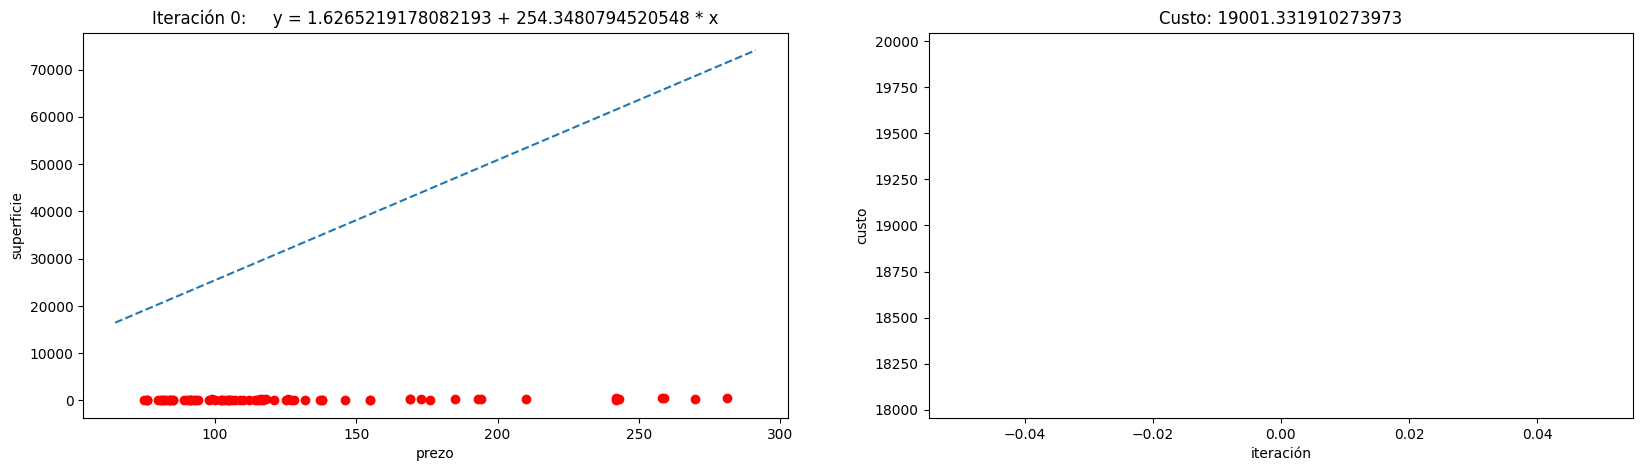

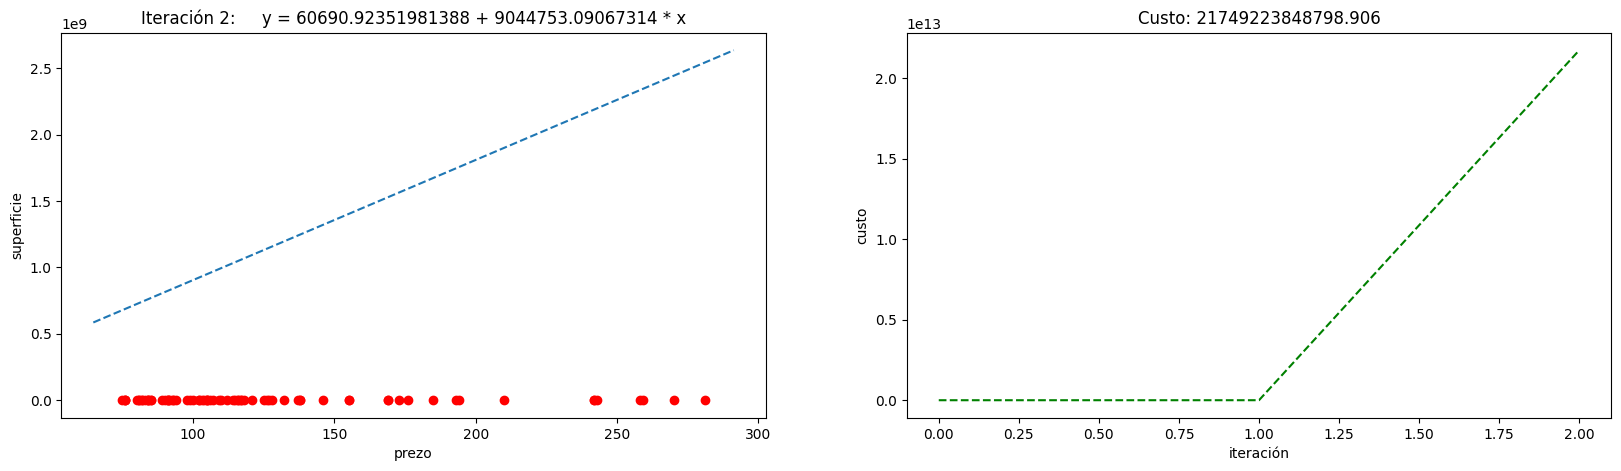

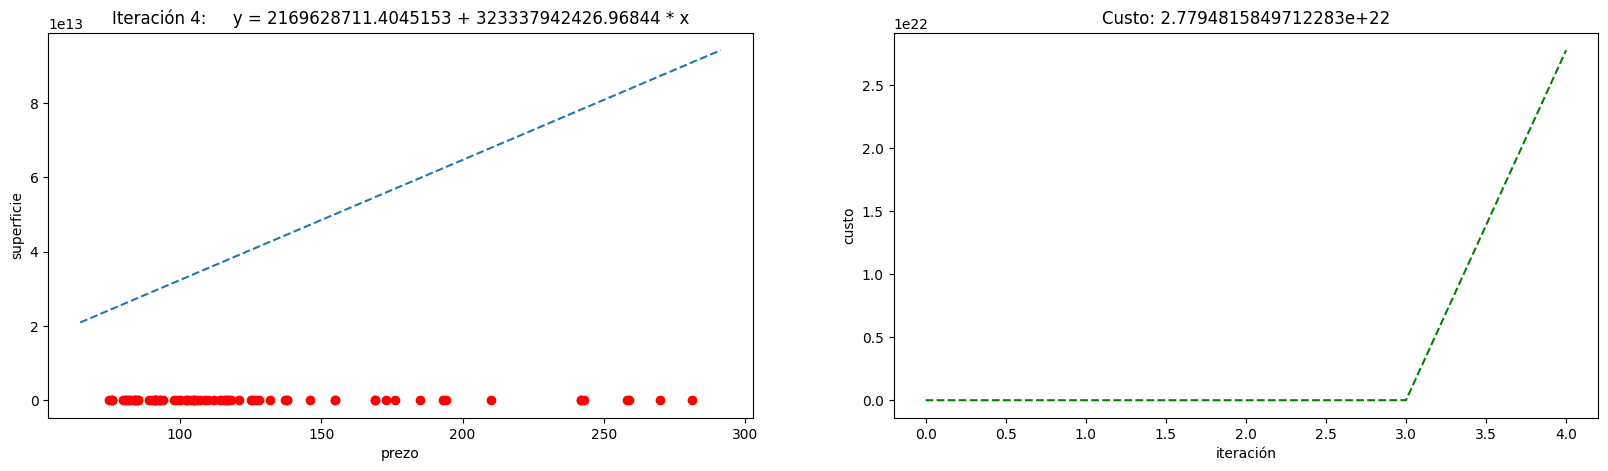

In [37]:
# Con alpha = 0.01 el algoritmo diverge
desc_grad(vivendas['superficie'], vivendas['prezo'], alpha = 0.01, iteracions = 6)

**Pregunta 6**

La salida muestra los dos coeficientes de la recta que ha calculado `LinearRegression` con todo el dataset: el término independiente (*Intercept*), $\theta_0 \approx$ -55,58, y la pendiente de la superficie, $\theta_1 \approx$ 1,711. Es decir, el modelo es precio = -55,58 + 1,711 · superficie: por cada metro cuadrado más, el precio estimado sube unos 1,71 miles de euros. Son los valores óptimos que buscaba el descenso del gradiente, que con 35 iteraciones no llegaba a alcanzar.

**Pregunta 7**

Porque el modelo ha calculado sus coeficientes precisamente para equivocarse lo menos posible con los datos de entrenamiento, así que el error sobre esos mismos datos sería demasiado optimista y no diría nada de cómo se comporta con viviendas nuevas, que es para lo que queremos el modelo.

Por eso se reserva un conjunto de test que el modelo no ve durante el entrenamiento. Al predecir esas viviendas y comparar con sus precios reales, se obtiene una medida más realista de su rendimiento con datos no vistos.

**Pregunta 8**

El *outlier* es la vivienda de 242 m² que cuesta solo 102,9 miles de euros. Como es muy grande pero muy barata, no sigue la tendencia del resto y hace que la recta quede más plana de lo que debería. Al quitarla y volver a entrenar, la recta se inclina más (la pendiente pasa de 1,51 a 1,76) y se ajusta mejor al resto de puntos.

El nuevo modelo también predice mejor: con el mismo conjunto de test, el error baja de unos 42 a unos 37 miles de euros. La correlación entre los precios reales y los predichos no cambia (0,92), porque solo dice si las predicciones siguen la tendencia de los datos, no cuánto se equivocan.

**************************************************************

# Modelado dun problema de regresión multivariante

## Enunciado

O problema sobre o que acabamos de traballar é un "exemplo xoguete". Na realidade, resultaría difícil poder predicir con exactitude o prezo dunha vivenda tendo en conta só unha variable (neste caso, a superficie). O máis probable é que outros factores contribúan a estimar un bo prezo para os inmobles. Algúns exemplos de outras variables continuas que se poderían empregar son a súa antigüidade, a distancia ao centro urbán máis próximo, o custo da vida na cidade, rexión ou país onde se ubica, etc.

Hai moitos portais de onde podes sacar datos. Por exemplo Kaggle, a maior comunidade de ciencia de datos e aprendizaxe automática online. Aquí tes algunhas ligazóns que podes consultar:

- ["friendly" datasets en Kaggle](https://www.kaggle.com/rtatman/fun-beginner-friendly-datasets)
- [outros datasets faciliños pensados para regresión](https://people.sc.fsu.edu/~jburkardt/datasets/regression/regression.html)

Imos traballar co dataset 80 cereals (https://www.kaggle.com/datasets/crawford/80-cereals). Carga o ficheiro cereal.csv e pon en práctica os teus coñecementos de regresión lineal. Escolle como variables preditoras aquelas que penses que poden estar linealmente correlacionada coa variable que queres predicir (*rating*). O único requerimento obrigatorio é **empregar exactamente DÚAS variables preditoras** no adestramento do modelo de regresión. 

Asegúrate de comprender ben o problema e a información que estás a manexar. Fai un breve estudo dos teus datos, incluíndo gráficas e comentarios propios. De ser preciso, aplica as etapas de preprocesado que consideres, pero coidado porque quizáis che implique facer un preprocesado demasiado complexo, para o que non estás preparado aínda. Logo, obtén o modelo e avalía o seu rendemento. Non pasa nada se finalmente non hai unha boa correlación entre as variables preditoras e a variable obxectivo e o modelo realiza malas predicións. A finalidade deste exercicio é abordar un problema real e que realices un bo procedemento de análise de datos en base ao aprendido.

Obtén un modelo seguindo as boas prácticas que levamos visto.

**************************************************************

## Resposta

Vamos a predecir el *rating* de los cereales usando dos variables predictoras.

In [38]:
cereais = pd.read_csv('cereal.csv', delimiter=',', header=0)  # Cargamos el csv
cereais.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      77 non-null     str    
 1   mfr       77 non-null     str    
 2   type      77 non-null     str    
 3   calories  77 non-null     int64  
 4   protein   77 non-null     int64  
 5   fat       77 non-null     int64  
 6   sodium    77 non-null     int64  
 7   fiber     77 non-null     float64
 8   carbo     77 non-null     float64
 9   sugars    77 non-null     int64  
 10  potass    77 non-null     int64  
 11  vitamins  77 non-null     int64  
 12  shelf     77 non-null     int64  
 13  weight    77 non-null     float64
 14  cups      77 non-null     float64
 15  rating    77 non-null     float64
dtypes: float64(5), int64(8), str(3)
memory usage: 9.8 KB


Hay 77 cereales y 16 variables, sin valores nulos. Tres columnas son de texto (`name`, `mfr` y `type`) y el resto son numéricas: la información nutricional de cada cereal y su `rating`, que es lo que queremos predecir.

In [39]:
cereais.describe()

,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
count,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000
mean,106.883117,2.545455,1.012987,159.675325,2.151948,14.597403,6.922078,96.077922,28.246753,2.207792,1.029610,0.821039,42.665705
std,19.484119,1.094790,1.006473,83.832295,2.383364,4.278956,4.444885,71.286813,22.342523,0.832524,0.150477,0.232716,14.047289
min,50.000000,1.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,1.000000,0.500000,0.250000,18.042851
25%,100.000000,2.000000,0.000000,130.000000,1.000000,12.000000,3.000000,40.000000,25.000000,1.000000,1.000000,0.670000,33.174094
50%,110.000000,3.000000,1.000000,180.000000,2.000000,14.000000,7.000000,90.000000,25.000000,2.000000,1.000000,0.750000,40.400208
75%,110.000000,3.000000,2.000000,210.000000,3.000000,17.000000,11.000000,120.000000,25.000000,3.000000,1.000000,1.000000,50.828392
max,160.000000,6.000000,5.000000,320.000000,14.000000,23.000000,15.000000,330.000000,100.000000,3.000000,1.500000,1.500000,93.704912


Algunos cereales tienen -1 en `carbo`, `sugars` o `potass`, que significa que falta el dato. Como son solo 3, los quitamos.

In [40]:
# Buscamos los cereales con algún -1
for i in cereais.index:
    if cereais['carbo'][i] < 0 or cereais['sugars'][i] < 0 or cereais['potass'][i] < 0:
        print(i, cereais['name'][i])

cereais = cereais.drop([4, 20, 57])  # Los quitamos

4 Almond Delight
20 Cream of Wheat (Quick)
57 Quaker Oatmeal


In [41]:
# Correlación de cada variable numérica con rating
cereais.loc[:, 'calories':'rating'].corr()['rating']

calories   -0.693785
protein     0.467162
fat        -0.405050
sodium     -0.383012
fiber       0.603411
carbo       0.055941
sugars     -0.755955
potass      0.415782
vitamins   -0.214481
shelf       0.051040
weight     -0.300461
cups       -0.222504
rating      1.000000
Name: rating, dtype: float64

Escogemos `sugars` (-0,76) y `fiber` (0,60), que están entre las más correlacionadas con `rating`. No usamos `calories` (-0,69) porque está bastante relacionada con `sugars` y repetiría casi la misma información:

In [42]:
cereais['sugars'].corr(cereais['calories'])  # Correlación entre sugars y calories

np.float64(0.569120535229035)

<Axes: xlabel='sugars', ylabel='rating'>

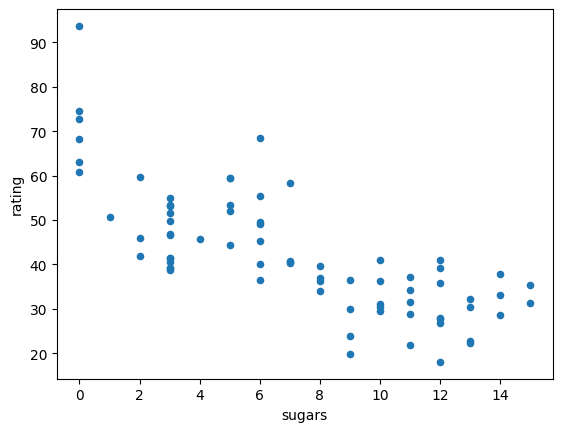

In [43]:
cereais.plot(kind='scatter', x='sugars', y='rating')

<Axes: xlabel='fiber', ylabel='rating'>

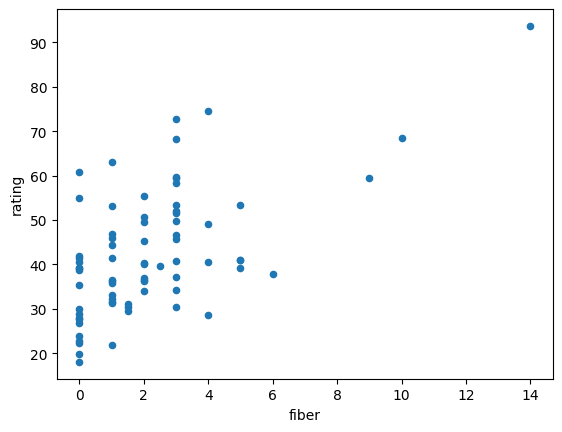

In [44]:
cereais.plot(kind='scatter', x='fiber', y='rating')

Con más azúcar el *rating* baja de forma bastante clara, y con más fibra sube, aunque con los puntos más dispersos.

In [45]:
# Separamos train (70%) y test (30%)
np.random.seed(SEED_VALUE)
cereais_train, cereais_test = train_test_split(cereais, test_size=0.3, random_state=SEED_VALUE)

# Entrenamos el modelo con sugars y fiber
cereais_train_X = cereais_train.loc[:, ['sugars', 'fiber']].astype(float)
cereais_train_Y = cereais_train.loc[:, 'rating']

modelo_cereais = LinearRegression()
np.random.seed(SEED_VALUE)
modelo_cereais.fit(cereais_train_X, cereais_train_Y)

coef_cereais = pd.DataFrame([modelo_cereais.intercept_, *modelo_cereais.coef_], ['(Intercept)', *cereais_train_X.columns], columns=['Coefficients'])
coef_cereais

,Coefficients
(Intercept),50.125704
sugars,-1.996680
fiber,2.925885


In [46]:
# Evaluamos con el conjunto de test
cereais_test_X = cereais_test.loc[:, ['sugars', 'fiber']].astype(float)
cereais_test_Y = cereais_test.loc[:, 'rating']

np.random.seed(SEED_VALUE)
predicions_cereais = modelo_cereais.predict(cereais_test_X)

print(np.sqrt(ecm(cereais_test_Y, predicions_cereais)))  # Raíz del error cuadrático
cereais_test_Y.corr(pd.Series(predicions_cereais, cereais_test_Y.index))  # Correlación

4.170306768332082


np.float64(0.9099795310705818)

Los cereales con más azúcar tienen peor *rating* y los que tienen más fibra, mejor. El modelo queda como rating = 50,13 - 2,00 · sugars + 2,93 · fiber. En test, la raíz del error es de unos 4,2 puntos y la correlación de 0,91, así que predice bastante bien con solo dos variables.

**************************************************************